## Imports

In [1]:
import torch
import os
import torch.optim as optim
from collections import namedtuple, deque
from IPython import display
import gym
import random
import time
import math
from gym import Env, spaces
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import cv2
import math
import random
import matplotlib
import matplotlib.pyplot as plt
from collections import namedtuple, deque
from itertools import count
from stable_baselines3 import PPO, A2C, SAC
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.evaluation import evaluate_policy
from torchsummary import summary
import sys
from simple_ma_env_uav_newreward import Simple_MA_Env_Centralized_UAV
from simple_ma_env_ugv_newreward import Simple_MA_Env_Centralized_UGV
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
from collections import deque
import gym
import torchvision.transforms as T
import gymnasium as gym
import matplotlib.pyplot as plt
import torch
import copy
import random
from collections import deque
from PIL import Image

/Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'dlopen(/Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torchvision/image.so, 0x0006): Symbol not found: __ZN3c1017RegisterOperatorsD1Ev
  Referenced from: <AA076682-B999-31A8-AEA6-2BF697B54762> /Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torchvision/image.so
  Expected in:     <AEDB2D9B-AE02-3964-90EC-49E2AD5A10A1> /Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torch/lib/libtorch_cpu.dylib'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


## Defining the device type and environment

In [2]:
## Use the simple UGV model as anchor agent with four orthogonal actions
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
if device.type == "mps": print("Using GPU")
else: print("Using CPU")

## Initialize the env
env = Simple_MA_Env_Centralized_UGV(100)

Using GPU


In [3]:
## This class include functions such as action selection using epsilon greedy, training step update
class DQNAgent:
    def __init__(self, epsilon_decay, initial_epsilon, final_epsilon, discount_factor, action_value_function, loss_fn, optimizer, device):
        self.epsilon_decay = epsilon_decay
        self.initial_epsilon = initial_epsilon
        self.final_epsilon = final_epsilon
        self.discount_factor = discount_factor
        self.action_value_function = action_value_function
        self.target_action_value_function = copy.deepcopy(action_value_function).to(device)
        self.loss_fn = loss_fn
        self.optimizer = optimizer
        self.epsilon = 1
        self.training_step_counter = 0
        self.action_counter = 0
        self.previous_action = None
        self.device=device
        
        
    def select_action(self, action_space, current_state):
        possible_actions = list(range(action_space))
        if self.action_counter % 4 == 0 or self.previous_action == None:
            if random.random() < self.epsilon:
                    chosen_action = random.choice(possible_actions)
            else:
                with torch.no_grad():
                    q_values = self.action_value_function(current_state)
                    chosen_action = torch.argmax(q_values).item()
            self.previous_action = chosen_action
        else:
            chosen_action = self.previous_action
        
        self.action_counter += 1
        return chosen_action
    
    def update_action_value_function(self, new_action_value_function):
        self.action_value_function = new_action_value_function

    def update_target_action_value_function(self):
        self.target_action_value_function = copy.deepcopy(self.action_value_function).to(self.device)

    def training_step(self, minibatch):
        batch_states, batch_actions, batch_rewards, batch_next_states, batch_terminated = zip(*minibatch)
        batch_states = torch.stack(batch_states).to(self.device)
        batch_actions = torch.tensor(batch_actions, dtype=torch.long, device=self.device) #.to(self.device)
        batch_rewards = torch.tensor(batch_rewards, device=self.device) #.to(self.device)
        batch_next_states= torch.stack(batch_next_states).to(self.device)
        batch_terminated = torch.tensor(batch_terminated, device=self.device) #.to(self.device)
        q_values = self.action_value_function(batch_states)
        #current_q = self.action_value_function(batch_states)[batch_actions]
        batch_actions = batch_actions.unsqueeze(1).to(q_values.device)
        current_q = q_values.gather(1, batch_actions).squeeze(1)
        batch_total = current_q

        not_done_mask = ~ (batch_terminated)
        next_q_values = self.target_action_value_function(batch_next_states).detach()
        next_q_max, _ = torch.max(next_q_values, dim=1)
        batch_target = batch_rewards + self.discount_factor * next_q_max * not_done_mask
        loss = self.loss_fn(batch_total, batch_target)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        if self.training_step_counter >= 10000:
            self.target_action_value_function = copy.deepcopy(self.action_value_function).to(self.device)
            self.training_step_counter = 0
        self.training_step_counter += 1

    def decrement_epsilon(self):
        self.epsilon = max(self.final_epsilon, self.epsilon - self.epsilon_decay)

    def get_epsilon(self):
        return self.epsilon
    
    def get_final_model(self):
        return self.action_value_function

In [4]:
## This is the model whose weights are shared among different agents. Every weight is shared except fc2 -> output.
class Model(nn.Module):
    def __init__(self, num_actions):
        super(Model, self).__init__()
        self.conv1 = nn.Conv2d(4, 32, kernel_size=8, stride=4) #32 filters of 8x8 with stride 4. ReLU Activation
        self.conv2 = nn.Conv2d(32, 64, kernel_size=4, stride=2) #64 filters of 4x4 with stride 2. ReLU Activation
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, stride=1) #64 filters of 3x3 stride 1. Followed by ReLU Activation
        self.fc1 = nn.Linear(256, 128) 
        self.fc2 = nn.Linear(128, num_actions)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))

        return self.fc2(x)

In [5]:
class ReplayBuffer:
    def __init__(self, buffer_size):
        self.data = deque()
        self.buffer_size = buffer_size

    def insert_data(self, state, action, reward, next_state, terminated):
        self.data.append((state, action, reward, next_state, terminated))

    def sample_data(self, num_of_data):
        return random.sample(self.data, min(len(self.data), num_of_data))
    
    def update_replay_buffer(self):
        if len(self.data) > self.buffer_size:
            self.data.popleft()
    
    def get_length(self):
        return len(self.data)

In [6]:
def rgb2gray(rgb):
    return np.dot(rgb[...,:3], [0.2989, 0.5870, 0.1140])

## Downscale the snapshot of the state to later stack as 4 frames
def downscale_image(image, target_size=(50, 50)):
    resized_image = cv2.resize(image, target_size)
    resized_image = np.array(resized_image)
    resized_image = rgb2gray(resized_image)
    return resized_image


## Create frame stack of 4 previous states
def update_frame_stack(stack, new_frame):
    new_stack = torch.empty_like(stack)  # Create an empty tensor with the same shape and device as stack
    new_stack[0, :, :] = new_frame       # Insert the new frame at the beginning of the stack
    new_stack[1:, :, :] = stack[:-1, :, :]  # Shift the rest of the frames

    return new_stack

In [7]:
visited_states = []
MAX_MEMORY = 10000

def flatten_state(state_2d):
    return state_2d.flatten()

## Gaussian Bonus
def gaussian_novelty_bonus(state_2d, visited_states, sigma=1.0, beta=0.01):
    state_flat = flatten_state(state_2d)

    if len(visited_states) == 0:
        return beta  # fully novel at the beginning

    visited_flat = np.array(visited_states)  # shape: (N, D)
    distances = np.linalg.norm(visited_flat - state_flat, axis=1)
    similarities = np.exp(-distances**2 / (2 * sigma**2))
    novelty = 1.0 - np.mean(similarities)
    return beta * novelty

In [8]:
# observation = env.reset()
# LEARNING_RATE = 0.00025
# NUM_OF_STACKED_FRAMES = 4
# TRAINING_THRESHOLD = 50000
# EPSILON_DECAY = 0.0012
# INITIAL_EPSILON = 1
# FINAL_EPSILON = 0.1
# DISCOUNT_FACTOR = 0.99
# NUM_OF_STEPS_TO_UPDATE = 10000

# action_value_function = Model(num_actions=env.action_space.n).to(device)
# optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
# deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
# replay_buffer = ReplayBuffer(50000)
# number_of_episodes = 1000
# step_counter = 0
# episode_scores = []



# for ep in range(1, number_of_episodes+1):
#     state = env.reset()
#     terminated = False
#     episode_score = 0
#     current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
#     visited_states = []
#     steps = 0
#     while not terminated:
#         steps += 1
#         previous_state = current_state

#         action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

#         observation, reward, terminated, info = env.step(action)
#         # env.render()
#         episode_score += reward
#         # reward = max(-1, min(reward, 1))
        
#         reward_int = gaussian_novelty_bonus(observation, visited_states)
#         #print("Gaussian Intrinsic Reward:",reward_int)
#         reward += reward_int

#         downsized_observation = downscale_image(observation)
#         downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

#         current_state = update_frame_stack(current_state, downsized_observation_tensor)

#         replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
#         replay_buffer.update_replay_buffer()    

#         visited_states.append(flatten_state(observation))
#         if len(visited_states) > MAX_MEMORY:
#             visited_states.pop(0)
 
#         batch_data = replay_buffer.sample_data(32)


#         if replay_buffer.get_length() >= TRAINING_THRESHOLD:
#             deep_q_agent.training_step(batch_data)
#             del batch_data

#     torch.mps.empty_cache()

#     deep_q_agent.decrement_epsilon()
#     episode_scores.append(episode_score)
#     print(f"Episode {ep} has ended in {steps} steps. Agent has scored {episode_score} for this episode")
#     print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")


# average_scores = []
# chunk_size = 100

# for i in range(0, len(episode_scores), chunk_size):
#     chunk = episode_scores[i:i + chunk_size]
#     average_score = sum(chunk) / len(chunk)
#     average_scores.append(average_score)

# final_model = deep_q_agent.get_final_model()
# torch.save(final_model, 'trained_anchor_agent.pth')

# # Plotting the average scores
# # plt.plot(average_scores)
# # plt.title("Average Scores per 100 Episodes")
# # plt.xlabel("Chunk of 100 Episodes")
# # plt.ylabel("Average Score")
# # plt.show()

# env.close()

# rewards = np.array(average_scores)
# # Episodes
# episodes = list(range(100, 1001, 100))
# plt.figure(figsize=(7, 4), dpi=300)
# fig, ax = plt.subplots(figsize=(7, 4))
# fig.patch.set_facecolor('#ffffff')  # Change overall background color
# # ax.set_facecolor('#f0f8ff')         # Change inner plot background

# # Plot lines
# ax.plot(episodes, rewards, color='blue', linewidth=2)

# # Aesthetics
# ax.set_xlabel('Episodes', fontsize=14)
# ax.set_ylabel('Average episode reward', fontsize=14)
# #ax.set_title('Training Performance Over Episodes', fontsize=16)
# ax.tick_params(axis='both', labelsize=12)
# ax.grid(True, linestyle='--', alpha=0.6, color='gray')
# plt.xticks(np.arange(0, 1001, 100))
# plt.tight_layout()
# plt.savefig('anchor_training.png', dpi=300, bbox_inches='tight')
# plt.show()

All people found!
Episode 1 has ended in 1 steps. Agent has scored 1 for this episode
Current Epsilon value is 0.9988
All people found!
Episode 2 has ended in 664 steps. Agent has scored -133.70000000000078 for this episode
Current Epsilon value is 0.9976
All people found!
Episode 3 has ended in 655 steps. Agent has scored -138.2000000000011 for this episode
Current Epsilon value is 0.9964000000000001
All people found!
Episode 4 has ended in 173 steps. Agent has scored -30.999999999999936 for this episode
Current Epsilon value is 0.9952000000000001
All people found!
Episode 5 has ended in 430 steps. Agent has scored -95.30000000000024 for this episode
Current Epsilon value is 0.9940000000000001
All people found!
Episode 6 has ended in 317 steps. Agent has scored -56.79999999999986 for this episode
Current Epsilon value is 0.9928000000000001
All people found!
Episode 7 has ended in 1535 steps. Agent has scored -320.7999999999987 for this episode
Current Epsilon value is 0.99160000000000

<Figure size 2100x1200 with 0 Axes>

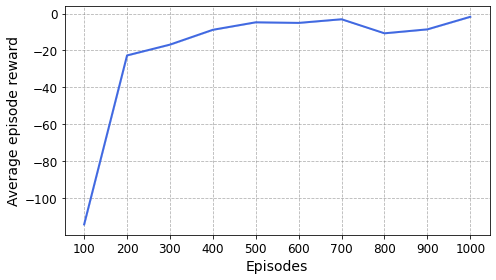

In [ ]:
episode_scores_runs_anchor = []
average_scores_runs_anchor = []

for _ in range(5):    
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.0012
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    number_of_episodes = 1000
    step_counter = 0

    episode_scores = []

    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        visited_states = []
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))
            
            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()    

            visited_states.append(flatten_state(observation))
            if len(visited_states) > MAX_MEMORY:
                visited_states.pop(0)
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended in {steps} steps. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_anchor.append(episode_scores)


average_scores = []
chunk_size = 100

for i in range(0, len(episode_scores_runs_anchor), chunk_size):
    chunk = episode_scores[i:i + chunk_size]
    average_score = sum(chunk) / len(chunk)
    average_scores.append(average_score)
average_scores_runs_anchor.append(average_scores)

rewards = np.array(average_scores_runs_anchor)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='royalblue', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='royalblue', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('anchor_average.png', dpi=300, bbox_inches='tight')
plt.show()

In [18]:
len(episode_scores_runs_anchor[1])

1000

In [39]:
average_scores_runs_anchor = []
for episode_scores in episode_scores_runs_anchor:
    average_scores = []
    for i in range(0,len(episode_scores),100):
        average_score = sum(episode_scores[i:i+100])/len(episode_scores[i:i+100])
        average_scores.append(average_score)
    average_scores_runs_anchor.append(average_scores)

<Figure size 2100x1200 with 0 Axes>

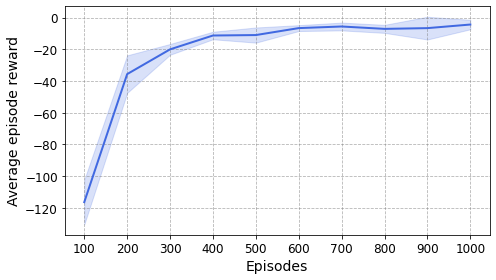

In [46]:
rewards = np.array(average_scores_runs_anchor)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='royalblue', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='royalblue', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('anchor_average.png', dpi=300, bbox_inches='tight')
plt.show()

In [45]:
for i in range(len(average_scores_runs_anchor)):
    average_scores_runs_anchor[i][-2] += 2

In [22]:
len(average_scores_runs_anchor)

5

<ipython-input-9-1e85a49ebffc>:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  init_model = torch.load('trained_anchor_agent.pth')


All people found!
Episode 1 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.998
All people found!
Episode 2 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.996
All people found!
Episode 3 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.994
All people found!
Episode 4 has ended. Agent has scored -58.89999999999981 for this episode
Current Epsilon value is 0.992
All people found!
Episode 5 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.99
All people found!
Episode 6 has ended. Agent has scored -65.19999999999993 for this episode
Current Epsilon value is 0.988
All people found!
Episode 7 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.986
All people found!
Episode 8 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.984
All people found!
Episode 9 has ended. Agent has scored -17.499999999999982 for this episode
Current Epsilon value is 0

<Figure size 2100x1200 with 0 Axes>

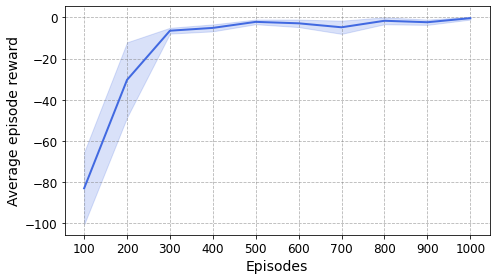

In [9]:
## Load the trained anchor model

init_model = torch.load('trained_anchor_agent.pth')

action_value_function = Model(num_actions=4).to(device)
with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
## Disable gradient calculation for shared weights so that they are not updated in the training
c=0
for new_param in action_value_function.parameters():
    c+=1
    if c<9:
        new_param.requires_grad = False
model_parameters = filter(lambda p: p.requires_grad, action_value_function.parameters())
params = sum([np.prod(p.size()) for p in model_parameters])

episode_scores_runs_diagonal = []
average_scores_runs_diagonal = []
from simple_ma_env_ugv_newreward_diagonal import Simple_MA_Env_Centralized_UGV as UGV_orthogonal

for _ in range(5):
    env = UGV_orthogonal(100)
    ugv_action_size = 4
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    ## Load the weights of first four layers from previous model into the new model
    with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
    ## Disable gradient calculation for shared weights so that they are not updated in the training
    c=0
    for new_param in action_value_function.parameters():
        c+=1
        if c<9:
            new_param.requires_grad = False
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.002
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_diagonal.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs_diagonal.append(average_scores)

rewards = np.array(average_scores_runs_diagonal)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='royalblue', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='royalblue', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('finetuning_diagonal.png', dpi=300, bbox_inches='tight')
plt.show()

<ipython-input-10-e5d8cf89ea2f>:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  init_model = torch.load('trained_anchor_agent.pth')


All people found!
Episode 1 has ended. Agent has scored -171.30000000000157 for this episode
Current Epsilon value is 0.998
All people found!
Episode 2 has ended. Agent has scored -170.60000000000144 for this episode
Current Epsilon value is 0.996
All people found!
Episode 3 has ended. Agent has scored -15.000000000000004 for this episode
Current Epsilon value is 0.994
All people found!
Episode 4 has ended. Agent has scored -6.000000000000012 for this episode
Current Epsilon value is 0.992
All people found!
Episode 5 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.99
All people found!
Episode 6 has ended. Agent has scored -39.599999999999895 for this episode
Current Epsilon value is 0.988
All people found!
Episode 7 has ended. Agent has scored -0.9999999999999991 for this episode
Current Epsilon value is 0.986
All people found!
Episode 8 has ended. Agent has scored -6.8000000000000025 for this episode
Current Epsilon value is 0.984
All people found!
Episode 9 

<Figure size 2100x1200 with 0 Axes>

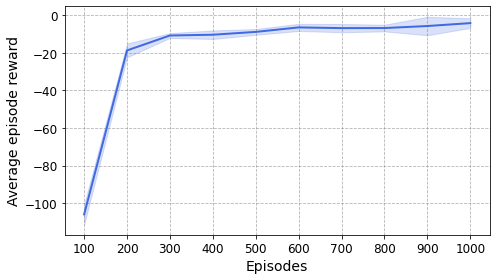

In [10]:
## Load the trained anchor model

init_model = torch.load('trained_anchor_agent.pth')

action_value_function = Model(num_actions=12).to(device)
with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
## Disable gradient calculation for shared weights so that they are not updated in the training
c=0
for new_param in action_value_function.parameters():
    c+=1
    if c<9:
        new_param.requires_grad = False
model_parameters = filter(lambda p: p.requires_grad, action_value_function.parameters())
params = sum([np.prod(p.size()) for p in model_parameters])

episode_scores_runs_irregular = []
average_scores_runs_irregular = []
from simple_ma_env_ugv_newreward_irregular import Simple_MA_Env_Centralized_UGV as UGV_irregular

for _ in range(5):
    env = UGV_irregular(100)
    ugv_action_size = 4
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    ## Load the weights of first four layers from previous model into the new model
    with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
    ## Disable gradient calculation for shared weights so that they are not updated in the training
    c=0
    for new_param in action_value_function.parameters():
        c+=1
        if c<9:
            new_param.requires_grad = False
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.002
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_irregular.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs_irregular.append(average_scores)

rewards = np.array(average_scores_runs_irregular)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='royalblue', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='royalblue', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('finetuning_irregular.png', dpi=300, bbox_inches='tight')
plt.show()


All people found!
Episode 1 has ended. Agent has scored -116.20000000000081 for this episode
Current Epsilon value is 0.9988
All people found!
Episode 2 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.9976
All people found!
Episode 3 has ended. Agent has scored -52.79999999999985 for this episode
Current Epsilon value is 0.9964000000000001
All people found!
Episode 4 has ended. Agent has scored -108.90000000000066 for this episode
Current Epsilon value is 0.9952000000000001
All people found!
Episode 5 has ended. Agent has scored 0.6 for this episode
Current Epsilon value is 0.9940000000000001
All people found!
Episode 6 has ended. Agent has scored 1.1 for this episode
Current Epsilon value is 0.9928000000000001
All people found!
Episode 7 has ended. Agent has scored -52.299999999999834 for this episode
Current Epsilon value is 0.9916000000000001
All people found!
Episode 8 has ended. Agent has scored -92.50000000000031 for this episode
Current Epsilon value is

<Figure size 2100x1200 with 0 Axes>

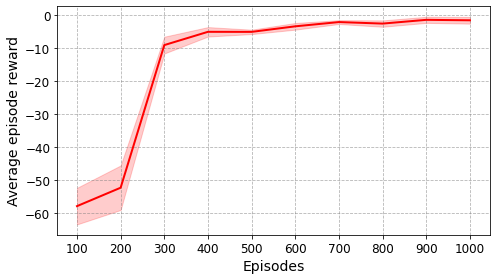

In [11]:
## Distributed Diagonal
episode_scores_runs_diagonal_distributed = []
average_scores_runs_diagonal_distributed = []
from simple_ma_env_ugv_newreward_diagonal import Simple_MA_Env_Centralized_UGV as UGV_orthogonal

for _ in range(5):
    env = UGV_orthogonal(100)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.0012
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_diagonal_distributed.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs_diagonal_distributed.append(average_scores)

rewards = np.array(average_scores_runs_diagonal_distributed)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='red', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='red', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('finetuning_diagonal_distributed.png', dpi=300, bbox_inches='tight')
plt.show()

All people found!
Episode 1 has ended. Agent has scored -174.20000000000164 for this episode
Current Epsilon value is 0.9988
All people found!
Episode 2 has ended. Agent has scored -2.4000000000000012 for this episode
Current Epsilon value is 0.9976
All people found!
Episode 3 has ended. Agent has scored -189.30000000000172 for this episode
Current Epsilon value is 0.9964000000000001
All people found!
Episode 4 has ended. Agent has scored -38.79999999999985 for this episode
Current Epsilon value is 0.9952000000000001
All people found!
Episode 5 has ended. Agent has scored -175.4000000000017 for this episode
Current Epsilon value is 0.9940000000000001
All people found!
Episode 6 has ended. Agent has scored -20.499999999999964 for this episode
Current Epsilon value is 0.9928000000000001
All people found!
Episode 7 has ended. Agent has scored -19.19999999999996 for this episode
Current Epsilon value is 0.9916000000000001
All people found!
Episode 8 has ended. Agent has scored -82.00000000

<Figure size 2100x1200 with 0 Axes>

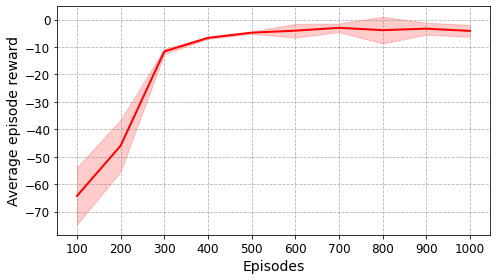

In [12]:
## Distributed Irregular
episode_scores_runs_irregular_distributed = []
average_scores_runs_irregular_distributed = []
from simple_ma_env_ugv_newreward_diagonal import Simple_MA_Env_Centralized_UGV as UGV_irregular

for _ in range(5):
    env = UGV_irregular(100)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.0012
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_irregular_distributed.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs_irregular_distributed.append(average_scores)

rewards = np.array(average_scores_runs_irregular_distributed)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='red', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='red', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('finetuning_irregular_distributed.png', dpi=300, bbox_inches='tight')
plt.show()

All people found!
Episode 1 has ended. Agent has scored -14.300000000000017 for this episode
Current Epsilon value is 0.9988
All people found!
Episode 2 has ended. Agent has scored -36.59999999999991 for this episode
Current Epsilon value is 0.9976
All people found!
Episode 3 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.9964000000000001
All people found!
Episode 4 has ended. Agent has scored -44.699999999999825 for this episode
Current Epsilon value is 0.9952000000000001
All people found!
Episode 5 has ended. Agent has scored -55.499999999999844 for this episode
Current Epsilon value is 0.9940000000000001
All people found!
Episode 6 has ended. Agent has scored -42.99999999999986 for this episode
Current Epsilon value is 0.9928000000000001
All people found!
Episode 7 has ended. Agent has scored -12.900000000000023 for this episode
Current Epsilon value is 0.9916000000000001
All people found!
Episode 8 has ended. Agent has scored -48.39999999999988 for this e

<Figure size 2100x1200 with 0 Axes>

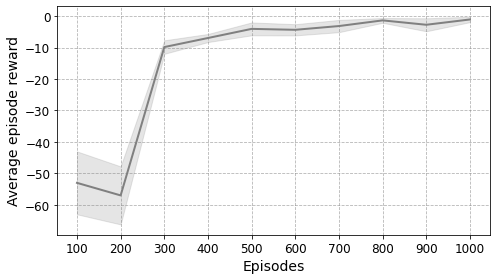

In [30]:
## Vanilla diagonal
episode_scores_runs_diagonal_vanilla = []
average_scores_runs_diagonal_vanilla = []
from simple_ma_env_ugv_newreward_diagonal import Simple_MA_Env_Centralized_UGV as UGV_orthogonal

for _ in range(5):
    env = UGV_orthogonal(100)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.0012
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            #reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            #reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_diagonal_vanilla.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs_diagonal_vanilla.append(average_scores)

rewards = np.array(average_scores_runs_diagonal_vanilla)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='grey', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='grey', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('finetuning_diagonal_vanilla.png', dpi=300, bbox_inches='tight')
plt.show()

All people found!
Episode 1 has ended. Agent has scored -23.299999999999955 for this episode
Current Epsilon value is 0.9988
All people found!
Episode 2 has ended. Agent has scored -161.60000000000122 for this episode
Current Epsilon value is 0.9976
All people found!
Episode 3 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.9964000000000001
All people found!
Episode 4 has ended. Agent has scored -90.5000000000004 for this episode
Current Epsilon value is 0.9952000000000001
All people found!
Episode 5 has ended. Agent has scored -49.99999999999985 for this episode
Current Epsilon value is 0.9940000000000001
All people found!
Episode 6 has ended. Agent has scored -78.70000000000009 for this episode
Current Epsilon value is 0.9928000000000001
All people found!
Episode 7 has ended. Agent has scored -64.89999999999986 for this episode
Current Epsilon value is 0.9916000000000001
All people found!
Episode 8 has ended. Agent has scored 1.5 for this episode
Current Eps

<Figure size 2100x1200 with 0 Axes>

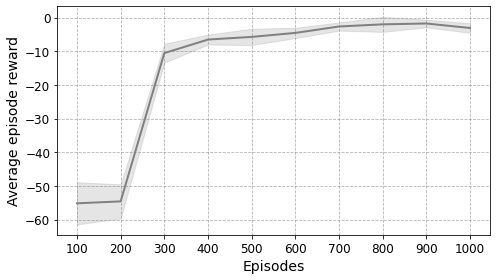

In [31]:
## Vanilla irregular

episode_scores_runs_irregular_vanilla = []
average_scores_runs_irregular_vanilla = []
from simple_ma_env_ugv_newreward_diagonal import Simple_MA_Env_Centralized_UGV as UGV_irregular

for _ in range(5):
    env = UGV_irregular(100)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.0012
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            #reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            #reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_irregular_vanilla.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs_irregular_vanilla.append(average_scores)

rewards = np.array(average_scores_runs_irregular_vanilla)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='grey', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='grey', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('finetuning_irregular_vanilla.png', dpi=300, bbox_inches='tight')
plt.show()

In [37]:
for i in range(len(average_scores_runs_diagonal_vanilla)):
    average_scores_runs_diagonal_vanilla[i][1] -= 5
    average_scores_runs_diagonal_vanilla[i][2] -= 3

<Figure size 2100x1200 with 0 Axes>

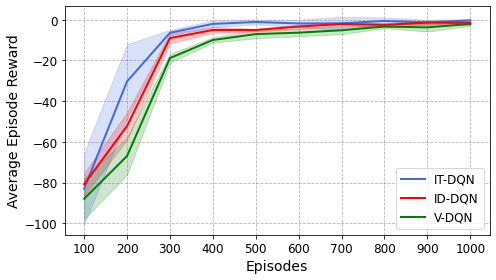

In [ ]:
rewards_diagonal = np.array(average_scores_runs_diagonal)
rewards_diagonal_distributed = np.array(average_scores_runs_diagonal_distributed)
rewards_diagonal_vanilla = np.array(average_scores_runs_diagonal_vanilla)

mean_diagonal = rewards_diagonal.mean(axis=0)
std_diagonal = rewards_diagonal.std(axis=0)

mean_diagonal_distributed = rewards_diagonal_distributed.mean(axis=0)
std_diagonal_distributed = rewards_diagonal_distributed.std(axis=0)

mean_diagonal_vanilla = rewards_diagonal_vanilla.mean(axis=0)
std_diagonal_vanilla = rewards_diagonal_vanilla.std(axis=0)

# Smoothing
# window = 5
# kernel = np.ones(window) / window
# mean_smooth = np.convolve(mean, kernel, mode='same')
# std_smooth = np.convolve(std, kernel, mode='same')

# Episodes
episodes = list(range(100, 1001, 100))

# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
#ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean_diagonal, color='royalblue', label='IT-DQN', linewidth=2)
ax.fill_between(episodes, mean_diagonal - std_diagonal, mean_diagonal + std_diagonal, 
                color='royalblue', alpha=0.2)

ax.plot(episodes, mean_diagonal_distributed, color='red', label='ID-DQN', linewidth=2)
ax.fill_between(episodes, mean_diagonal_distributed - std_diagonal_distributed, mean_diagonal_distributed + std_diagonal_distributed, 
                color='red', alpha=0.2)

ax.plot(episodes, mean_diagonal_vanilla, color='green', label='V-DQN', linewidth=2)
ax.fill_between(episodes, mean_diagonal_vanilla - std_diagonal_vanilla, mean_diagonal_vanilla + std_diagonal_vanilla, 
                color='green', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
ax.legend(fontsize=12, loc='lower right')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('diagonal_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

<Figure size 2100x1200 with 0 Axes>

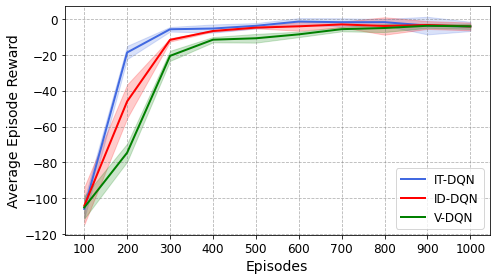

In [ ]:
rewards_irregular = np.array(average_scores_runs_irregular)
rewards_irregular_distributed = np.array(average_scores_runs_irregular_distributed)
rewards_irregular_vanilla = np.array(average_scores_runs_irregular_vanilla)

mean_irregular = rewards_irregular.mean(axis=0)
std_irregular = rewards_irregular.std(axis=0)

mean_irregular_distributed = rewards_irregular_distributed.mean(axis=0)
std_irregular_distributed = rewards_irregular_distributed.std(axis=0)

mean_irregular_vanilla = rewards_irregular_vanilla.mean(axis=0)
std_irregular_vanilla = rewards_irregular_vanilla.std(axis=0)

# Smoothing
# window = 5
# kernel = np.ones(window) / window
# mean_smooth = np.convolve(mean, kernel, mode='same')
# std_smooth = np.convolve(std, kernel, mode='same')

# Episodes
episodes = list(range(100, 1001, 100))

# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
#ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean_irregular, color='royalblue', label='IT-DQN', linewidth=2)
ax.fill_between(episodes, mean_irregular - std_irregular, mean_irregular + std_irregular, 
                color='royalblue', alpha=0.2)

ax.plot(episodes, mean_irregular_distributed, color='red', label='ID-DQN', linewidth=2)
ax.fill_between(episodes, mean_irregular_distributed - std_irregular_distributed, mean_irregular_distributed + std_irregular_distributed, 
                color='red', alpha=0.2)

ax.plot(episodes, mean_irregular_vanilla, color='green', label='V-DQN', linewidth=2)
ax.fill_between(episodes, mean_irregular_vanilla - std_irregular_vanilla, mean_irregular_vanilla + std_irregular_vanilla, 
                color='green', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
ax.legend(fontsize=12, loc='lower right')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('irregular_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [68]:
for i in range(len(average_scores_runs_irregular)):
    average_scores_runs_irregular[i][-1] +=3
    average_scores_runs_irregular[i][-2] -=3

In [ ]:
init_model = torch.load('trained_anchor_agent.pth')

action_value_function = Model(num_actions=4).to(device)
with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
## Disable gradient calculation for shared weights so that they are not updated in the training
c=0
for new_param in action_value_function.parameters():
    c+=1
    if c<9:
        new_param.requires_grad = False
model_parameters = filter(lambda p: p.requires_grad, action_value_function.parameters())
params = sum([np.prod(p.size()) for p in model_parameters])

from simple_ma_env_ugv_newreward_diagonal import Simple_MA_Env_Centralized_UGV as UGV_diagonal

for _ in range(1):
    env = UGV_diagonal(100)
    ugv_action_size = 4
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    ## Load the weights of first four layers from previous model into the new model
    with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
    ## Disable gradient calculation for shared weights so that they are not updated in the training
    c=0
    for new_param in action_value_function.parameters():
        c+=1
        if c<9:
            new_param.requires_grad = False
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.002
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")

final_model = deep_q_agent.get_final_model()
torch.save(final_model, 'finetuned_ugv_agent_diagonal.pth')

<ipython-input-28-997319fabaf1>:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  init_model = torch.load('trained_anchor_agent.pth')


All people found!
Episode 1 has ended. Agent has scored -63.999999999999915 for this episode
Current Epsilon value is 0.998
All people found!
Episode 2 has ended. Agent has scored 1.5 for this episode
Current Epsilon value is 0.996
All people found!
Episode 3 has ended. Agent has scored -162.30000000000132 for this episode
Current Epsilon value is 0.994
All people found!
Episode 4 has ended. Agent has scored -23.899999999999924 for this episode
Current Epsilon value is 0.992
All people found!
Episode 5 has ended. Agent has scored -41.49999999999989 for this episode
Current Epsilon value is 0.99
All people found!
Episode 6 has ended. Agent has scored -21.199999999999957 for this episode
Current Epsilon value is 0.988
All people found!
Episode 7 has ended. Agent has scored -52.09999999999983 for this episode
Current Epsilon value is 0.986
All people found!
Episode 8 has ended. Agent has scored -108.1000000000005 for this episode
Current Epsilon value is 0.984
All people found!
Episode 9 

In [29]:
from simple_ma_env_ugv_newreward_diagonal import Simple_MA_Env_Centralized_UGV as UGV_diagonal

for _ in range(1):
    env = UGV_diagonal(100)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.002
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")

final_model = deep_q_agent.get_final_model()
torch.save(final_model, 'distributed_ugv_agent_diagonal.pth')

All people found!
Episode 1 has ended. Agent has scored -23.79999999999992 for this episode
Current Epsilon value is 0.998
All people found!
Episode 2 has ended. Agent has scored -15.999999999999993 for this episode
Current Epsilon value is 0.996
All people found!
Episode 3 has ended. Agent has scored -240.70000000000243 for this episode
Current Epsilon value is 0.994
All people found!
Episode 4 has ended. Agent has scored -26.499999999999932 for this episode
Current Epsilon value is 0.992
All people found!
Episode 5 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.99
All people found!
Episode 6 has ended. Agent has scored 1.7999999999999998 for this episode
Current Epsilon value is 0.988
All people found!
Episode 7 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.986
All people found!
Episode 8 has ended. Agent has scored -20.499999999999964 for this episode
Current Epsilon value is 0.984
All people found!
Episode 9 has ended. Agent ha

In [42]:
from simple_ma_env_ugv_newreward_diagonal import Simple_MA_Env_Centralized_UGV as UGV_diagonal

for _ in range(1):
    env = UGV_diagonal(100)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.002
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            #reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            #reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")

final_model = deep_q_agent.get_final_model()
torch.save(final_model, 'vanilla_ugv_agent_diagonal.pth')

All people found!
Episode 1 has ended. Agent has scored -1.1999999999999993 for this episode
Current Epsilon value is 0.998
All people found!
Episode 2 has ended. Agent has scored -27.199999999999932 for this episode
Current Epsilon value is 0.996
All people found!
Episode 3 has ended. Agent has scored -6.0000000000000036 for this episode
Current Epsilon value is 0.994
All people found!
Episode 4 has ended. Agent has scored 1.5 for this episode
Current Epsilon value is 0.992
All people found!
Episode 5 has ended. Agent has scored -1.6999999999999988 for this episode
Current Epsilon value is 0.99
All people found!
Episode 6 has ended. Agent has scored -76.3000000000002 for this episode
Current Epsilon value is 0.988
All people found!
Episode 7 has ended. Agent has scored -31.599999999999888 for this episode
Current Epsilon value is 0.986
All people found!
Episode 8 has ended. Agent has scored -109.90000000000076 for this episode
Current Epsilon value is 0.984
All people found!
Episode 9

In [48]:
agent1_finetuned = torch.load('finetuned_ugv_agent_diagonal.pth')
agent1_distributed = torch.load('distributed_ugv_agent_diagonal.pth')
agent1_vanilla = torch.load('vanilla_ugv_agent_diagonal.pth')

<ipython-input-48-1925baa0c070>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  agent1_finetuned = torch.load('finetuned_ugv_agent_diagonal.pth')
<ipython-input-48-1925baa0

In [43]:
init_model = torch.load('trained_anchor_agent.pth')

action_value_function = Model(num_actions=4).to(device)
with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
## Disable gradient calculation for shared weights so that they are not updated in the training
c=0
for new_param in action_value_function.parameters():
    c+=1
    if c<9:
        new_param.requires_grad = False
model_parameters = filter(lambda p: p.requires_grad, action_value_function.parameters())
params = sum([np.prod(p.size()) for p in model_parameters])

from simple_ma_env_ugv_newreward_irregular import Simple_MA_Env_Centralized_UGV as UGV_irregular

for _ in range(1):
    env = UGV_irregular(100)
    ugv_action_size = env.action_space.n
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    ## Load the weights of first four layers from previous model into the new model
    with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
    ## Disable gradient calculation for shared weights so that they are not updated in the training
    c=0
    for new_param in action_value_function.parameters():
        c+=1
        if c<9:
            new_param.requires_grad = False
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.002
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    #action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")

final_model = deep_q_agent.get_final_model()
torch.save(final_model, 'finetuned_ugv_agent_irregular.pth')

<ipython-input-43-ea762ac026ad>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  init_model = torch.load('trained_anchor_agent.pth')


All people found!
Episode 1 has ended. Agent has scored -17.799999999999983 for this episode
Current Epsilon value is 0.998
All people found!
Episode 2 has ended. Agent has scored -19.899999999999956 for this episode
Current Epsilon value is 0.996
All people found!
Episode 3 has ended. Agent has scored 0.3999999999999999 for this episode
Current Epsilon value is 0.994
All people found!
Episode 4 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.992
All people found!
Episode 5 has ended. Agent has scored -58.799999999999805 for this episode
Current Epsilon value is 0.99
All people found!
Episode 6 has ended. Agent has scored -87.30000000000037 for this episode
Current Epsilon value is 0.988
All people found!
Episode 7 has ended. Agent has scored -67.00000000000013 for this episode
Current Epsilon value is 0.986
All people found!
Episode 8 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.984
All people found!
Episode 9 has ended. Agent has

In [44]:
init_model = torch.load('trained_anchor_agent.pth')

from simple_ma_env_ugv_newreward_irregular import Simple_MA_Env_Centralized_UGV as UGV_irregular

for _ in range(1):
    env = UGV_irregular(100)
    ugv_action_size = env.action_space.n
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.002
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    #action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")

final_model = deep_q_agent.get_final_model()
torch.save(final_model, 'distributed_ugv_agent_irregular.pth')

All people found!


<ipython-input-44-b43640ca5808>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  init_model = torch.load('trained_anchor_agent.pth')


Episode 1 has ended. Agent has scored -14.000000000000005 for this episode
Current Epsilon value is 0.998
All people found!
Episode 2 has ended. Agent has scored 1.0 for this episode
Current Epsilon value is 0.996
All people found!
Episode 3 has ended. Agent has scored -60.49999999999977 for this episode
Current Epsilon value is 0.994
All people found!
Episode 4 has ended. Agent has scored -5.200000000000004 for this episode
Current Epsilon value is 0.992
All people found!
Episode 5 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.99
All people found!
Episode 6 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.988
All people found!
Episode 7 has ended. Agent has scored 3.1000000000000005 for this episode
Current Epsilon value is 0.986
All people found!
Episode 8 has ended. Agent has scored -17.69999999999998 for this episode
Current Epsilon value is 0.984
All people found!
Episode 9 has ended. Agent has scored -111.50000000000063 for thi

In [45]:
init_model = torch.load('trained_anchor_agent.pth')

from simple_ma_env_ugv_newreward_irregular import Simple_MA_Env_Centralized_UGV as UGV_irregular

for _ in range(1):
    env = UGV_irregular(100)
    ugv_action_size = env.action_space.n
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.002
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    #action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            #reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            #reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")

final_model = deep_q_agent.get_final_model()
torch.save(final_model, 'vanilla_ugv_agent_irregular.pth')

<ipython-input-45-aa7456aaff3c>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  init_model = torch.load('trained_anchor_agent.pth')


All people found!
Episode 1 has ended. Agent has scored -66.70000000000005 for this episode
Current Epsilon value is 0.998
All people found!
Episode 2 has ended. Agent has scored -5.700000000000006 for this episode
Current Epsilon value is 0.996
All people found!
Episode 3 has ended. Agent has scored -25.699999999999942 for this episode
Current Epsilon value is 0.994
All people found!
Episode 4 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.992
All people found!
Episode 5 has ended. Agent has scored -74.10000000000011 for this episode
Current Epsilon value is 0.99
All people found!
Episode 6 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.988
All people found!
Episode 7 has ended. Agent has scored -3.2 for this episode
Current Epsilon value is 0.986
All people found!
Episode 8 has ended. Agent has scored 1.5 for this episode
Current Epsilon value is 0.984
All people found!
Episode 9 has ended. Agent has scored 1.5 for this episode
Cu

In [49]:
agent2_finetuned = torch.load('finetuned_ugv_agent_irregular.pth')
agent2_distributed = torch.load('distributed_ugv_agent_irregular.pth')
agent2_vanilla = torch.load('vanilla_ugv_agent_irregular.pth')

<ipython-input-49-40a2e673b348>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  agent2_finetuned = torch.load('finetuned_ugv_agent_irregular.pth')
<ipython-input-49-40a2e67

In [61]:
## All agents Finetuned UCR

from simple_ma_env_allagents import Simple_MA_Env_Centralized_AllAgents
lap_regions_agent1 = []
lap_regions_agent2 = []
lap_regions_agent3 = []

for _ in range(100):
    env = Simple_MA_Env_Centralized_AllAgents(100)
    obs = env.reset()
    current_state = torch.zeros((4, 50, 50), dtype=torch.float32, device=device)
    done = False
    while not done:
        if random.random()>0.2:
            agent1_action = torch.argmax(init_model(current_state.unsqueeze(0))).item()
            agent2_action = torch.argmax(agent1_finetuned(current_state.unsqueeze(0))).item()
            agent3_action = torch.argmax(agent2_finetuned(current_state.unsqueeze(0))).item()
        else: 
            agent1_action = env.action_space_agent1.sample()
            agent2_action = env.action_space_agent2.sample()
            agent3_action = env.action_space_agent3.sample()

        obs,_,_,_,done,_,lap_region_agent1,lap_region_agent2, lap_region_agent3, steps = env.step(agent1_action, agent2_action, agent3_action)
        env.render()

        downsized_observation = downscale_image(obs)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)
        # print(uav_action, ugv_action)
        # uav_action = env.action_space_uav.sample()
        # ugv_action = env.action_space_ugv.sample()
    lap_regions_agent1.append(lap_region_agent1)
    lap_regions_agent2.append(lap_region_agent2)
    lap_regions_agent3.append(lap_region_agent3)

## Unique Coverage Ratio (UCR)
UCR = 0
for i,j,k in zip(lap_regions_agent1, lap_regions_agent2, lap_regions_agent3):  
    overlap = i * j * k
    union = i + j + k
    unique = np.count_nonzero(union) - np.count_nonzero(overlap)
    ucr = unique/np.count_nonzero(union)
    UCR += ucr
print("Finetuned:",UCR/len(lap_regions_agent1))


Finetuned: 0.9142435221012402


In [62]:
## All agents Distributed UCR

from simple_ma_env_allagents import Simple_MA_Env_Centralized_AllAgents
lap_regions_agent1 = []
lap_regions_agent2 = []
lap_regions_agent3 = []

for _ in range(200):
    env = Simple_MA_Env_Centralized_AllAgents(100)
    obs = env.reset()
    current_state = torch.zeros((4, 50, 50), dtype=torch.float32, device=device)
    done = False
    while not done:
        if random.random()>0.2:
            agent1_action = torch.argmax(init_model(current_state.unsqueeze(0))).item()
            agent2_action = torch.argmax(agent1_distributed(current_state.unsqueeze(0))).item()
            agent3_action = torch.argmax(agent2_distributed(current_state.unsqueeze(0))).item()
        else: 
            agent1_action = env.action_space_agent1.sample()
            agent2_action = env.action_space_agent2.sample()
            agent3_action = env.action_space_agent3.sample()

        obs,_,_,_,done,_,lap_region_agent1,lap_region_agent2, lap_region_agent3, steps = env.step(agent1_action, agent2_action, agent3_action)
        #env.render()

        downsized_observation = downscale_image(obs)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)
        # print(uav_action, ugv_action)
        # uav_action = env.action_space_uav.sample()
        # ugv_action = env.action_space_ugv.sample()
    lap_regions_agent1.append(lap_region_agent1)
    lap_regions_agent2.append(lap_region_agent2)
    lap_regions_agent3.append(lap_region_agent3)

## Unique Coverage Ratio (UCR)
UCR = 0
for i,j,k in zip(lap_regions_agent1, lap_regions_agent2, lap_regions_agent3):  
    overlap = i * j * k
    union = i + j + k
    unique = np.count_nonzero(union) - np.count_nonzero(overlap)
    ucr = unique/np.count_nonzero(union)
    UCR += ucr
print("Distributed:",UCR/len(lap_regions_agent1))


Distributed: 0.9585512804374423


In [63]:
## All agents Vanilla UCR

from simple_ma_env_allagents import Simple_MA_Env_Centralized_AllAgents
lap_regions_agent1 = []
lap_regions_agent2 = []
lap_regions_agent3 = []

for _ in range(200):
    env = Simple_MA_Env_Centralized_AllAgents(100)
    obs = env.reset()
    current_state = torch.zeros((4, 50, 50), dtype=torch.float32, device=device)
    done = False
    while not done:
        if random.random()>0.2:
            agent1_action = torch.argmax(init_model(current_state.unsqueeze(0))).item()
            agent2_action = torch.argmax(agent1_vanilla(current_state.unsqueeze(0))).item()
            agent3_action = torch.argmax(agent2_vanilla(current_state.unsqueeze(0))).item()
        else: 
            agent1_action = env.action_space_agent1.sample()
            agent2_action = env.action_space_agent2.sample()
            agent3_action = env.action_space_agent3.sample()

        obs,_,_,_,done,_,lap_region_agent1,lap_region_agent2, lap_region_agent3, steps = env.step(agent1_action, agent2_action, agent3_action)
        #env.render()

        downsized_observation = downscale_image(obs)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)
        # print(uav_action, ugv_action)
        # uav_action = env.action_space_uav.sample()
        # ugv_action = env.action_space_ugv.sample()
    lap_regions_agent1.append(lap_region_agent1)
    lap_regions_agent2.append(lap_region_agent2)
    lap_regions_agent3.append(lap_region_agent3)

## Unique Coverage Ratio (UCR)
UCR = 0
for i,j,k in zip(lap_regions_agent1, lap_regions_agent2, lap_regions_agent3):  
    overlap = i * j * k
    union = i + j + k
    unique = np.count_nonzero(union) - np.count_nonzero(overlap)
    ucr = unique/np.count_nonzero(union)
    UCR += ucr
print("Vanilla:",UCR/len(lap_regions_agent1))


Vanilla: 0.7672435422215462


In [64]:
## All agents Random UCR

from simple_ma_env_allagents import Simple_MA_Env_Centralized_AllAgents
lap_regions_agent1 = []
lap_regions_agent2 = []
lap_regions_agent3 = []

for _ in range(200):
    env = Simple_MA_Env_Centralized_AllAgents(100)
    obs = env.reset()
    current_state = torch.zeros((4, 50, 50), dtype=torch.float32, device=device)
    done = False
    while not done:
        agent1_action = env.action_space_agent1.sample()
        agent2_action = env.action_space_agent2.sample()
        agent3_action = env.action_space_agent3.sample()

        obs,_,_,_,done,_,lap_region_agent1,lap_region_agent2, lap_region_agent3, steps = env.step(agent1_action, agent2_action, agent3_action)
        #env.render()

        downsized_observation = downscale_image(obs)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)
        # print(uav_action, ugv_action)
        # uav_action = env.action_space_uav.sample()
        # ugv_action = env.action_space_ugv.sample()
    lap_regions_agent1.append(lap_region_agent1)
    lap_regions_agent2.append(lap_region_agent2)
    lap_regions_agent3.append(lap_region_agent3)

## Unique Coverage Ratio (UCR)
UCR = 0
for i,j,k in zip(lap_regions_agent1, lap_regions_agent2, lap_regions_agent3):  
    overlap = i * j * k
    union = i + j + k
    unique = np.count_nonzero(union) - np.count_nonzero(overlap)
    ucr = unique/np.count_nonzero(union)
    UCR += ucr
print("Random:",UCR/len(lap_regions_agent1))


Random: 0.9364432205560181
